# Session 5 exercise: simple linear regression on Armand's Pizza

> **Armand's Pizza has 10 restaurants near college campuses. Does the student population near a
> branch predict its annual sales? Fit the line, read the output, check the plot, and predict for
> a new site.**

This is the exact skill the Session 6 in-class test asks for: fit a simple regression and read it.
Work through it yourself. Predict before each cell.

The data is only 10 rows, so it is defined inline. Nothing to upload.

## Step 0, the data

`student_population` is in thousands; `annual_sales` is in thousands of euro.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pizza = pd.DataFrame({
    "student_population": [2, 6, 8, 8, 12, 16, 20, 20, 22, 26],
    "annual_sales":       [58, 105, 88, 118, 117, 137, 157, 169, 149, 202],
})
print(pizza)

   student_population  annual_sales
0                   2            58
1                   6           105
2                   8            88
3                   8           118
4                  12           117
5                  16           137
6                  20           157
7                  20           169
8                  22           149
9                  26           202


## Step 1, look before you model

Always plot first (remember Anscombe). Does the relationship look like a line?

**Predict:** eyeball the cloud. Roughly how much do sales rise for each extra 1,000 students?

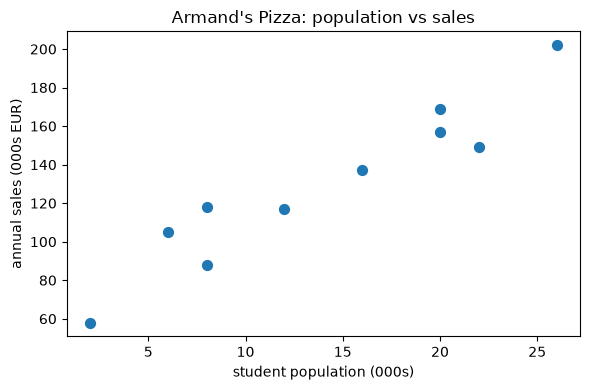

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(pizza["student_population"], pizza["annual_sales"], s=50)
ax.set_xlabel("student population (000s)"); ax.set_ylabel("annual sales (000s EUR)")
ax.set_title("Armand's Pizza: population vs sales")
plt.tight_layout(); plt.show()

## Step 2, fit the line

`scipy.stats.linregress` fits `sales = intercept + slope x population` and returns everything you
need to read the three output blocks.

In [3]:
x = pizza["student_population"]
y = pizza["annual_sales"]
reg = stats.linregress(x, y)

print(f"intercept (a) = {reg.intercept:.2f}")
print(f"slope (b)     = {reg.slope:.3f}")
print(f"R-squared     = {reg.rvalue**2:.3f}")
print(f"slope p-value = {reg.pvalue:.2e}")
print(f"\nThe line: sales = {reg.intercept:.1f} + {reg.slope:.2f} x population")

intercept (a) = 60.00
slope (b)     = 5.000
R-squared     = 0.903
slope p-value = 2.55e-05

The line: sales = 60.0 + 5.00 x population


## Step 3, read the three output blocks

Whatever the software, read the same three things:

1. **Model fit (R-squared):** what share of the variation in sales does the line explain?
2. **Is the predictor real (slope p-value)?** is the slope significantly different from zero?
3. **Coefficients (slope, intercept):** what do they mean in business terms?

Fill in the blanks out loud before running the cell.

In [4]:
r2 = reg.rvalue**2
print(f"1. R-squared = {r2:.2f}: the line explains about {r2*100:.0f}% of the variation in sales.")
print(f"2. slope p-value = {reg.pvalue:.2e}: the slope is "
      f"{'significantly different from zero' if reg.pvalue < 0.05 else 'not significant'}.")
print(f"3. slope = {reg.slope:.2f}: each extra 1,000 students is worth about "
      f"{reg.slope:.0f}k EUR in annual sales; intercept = {reg.intercept:.0f}k is the model's "
      f"baseline at zero students (well outside the data, so read it with care).")

1. R-squared = 0.90: the line explains about 90% of the variation in sales.
2. slope p-value = 2.55e-05: the slope is significantly different from zero.
3. slope = 5.00: each extra 1,000 students is worth about 5k EUR in annual sales; intercept = 60k is the model's baseline at zero students (well outside the data, so read it with care).


## Step 4, check the plot and the residuals

A good fit still needs a look at what it misses. The residuals (actual minus predicted) should
scatter randomly around zero with no pattern and no single point dominating.

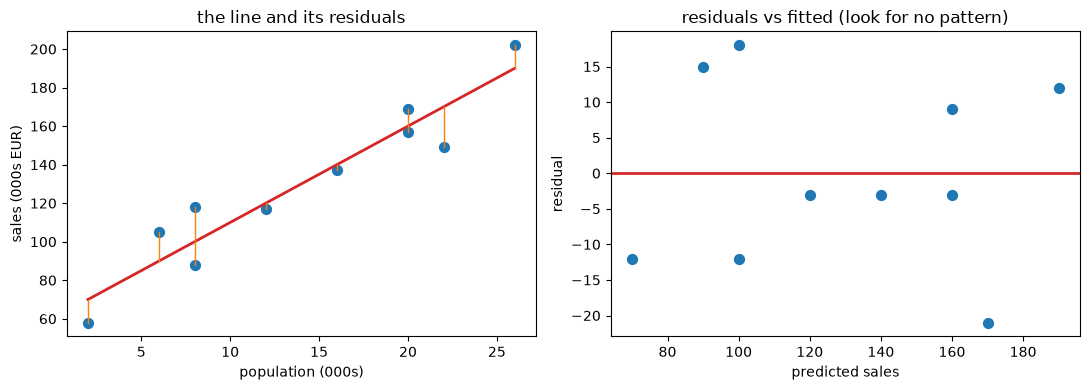

In [5]:
pred = reg.intercept + reg.slope * x
resid = y - pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, y, s=50)
xs = np.array([x.min(), x.max()])
axes[0].plot(xs, reg.intercept + reg.slope * xs, color="C3", lw=2)
for xi, yi, pi in zip(x, y, pred):
    axes[0].plot([xi, xi], [yi, pi], color="C1", lw=1)
axes[0].set_title("the line and its residuals"); axes[0].set_xlabel("population (000s)")
axes[0].set_ylabel("sales (000s EUR)")

axes[1].scatter(pred, resid, s=50); axes[1].axhline(0, color="C3", lw=2)
axes[1].set_title("residuals vs fitted (look for no pattern)")
axes[1].set_xlabel("predicted sales"); axes[1].set_ylabel("residual")
plt.tight_layout(); plt.show()

## Step 5, predict for a new site

A new campus has a student population of 15 (thousand). Predict the branch's annual sales, and say
how much to trust the number.

In [6]:
new_pop = 15
point = reg.intercept + reg.slope * new_pop
print(f"predicted annual sales at population 15k: about {point:.0f}k EUR")
print(f"\nTrust it because the model is strong (R-squared {reg.rvalue**2:.2f}) and 15 sits inside "
      f"the data range (2 to 26). A prediction far outside that range would be extrapolation, "
      f"which the model cannot vouch for. And a tight fit is not proof that population causes "
      f"sales; it is a strong, usable association.")

predicted annual sales at population 15k: about 135k EUR

Trust it because the model is strong (R-squared 0.90) and 15 sits inside the data range (2 to 26). A prediction far outside that range would be extrapolation, which the model cannot vouch for. And a tight fit is not proof that population causes sales; it is a strong, usable association.


---

### Ask Claude, then judge the answer

> *Here is my Armand's Pizza regression output: slope 5.0, intercept 60, R-squared 0.90, slope
> p < 0.001. Write a three-sentence recommendation for where to open the next branch, and tell me
> one thing this model cannot justify.*

The model predicts; it does not prove causation and it cannot speak to sites outside the data range.
A good answer says so.

### Debrief
- What does the slope mean in euros, and the intercept?
- Would you trust a prediction for a campus of 50,000 students? Why not?
- If the residual plot showed a clear curve, what would that tell you to do?